# 02d · Bow-tie structure of the forwarding graph (exploratory)

Suggested by Jussara after the mid-term (`docs/DECISIONS.md` **D24**). The bow-tie decomposition of
Broder et al. (2000) splits a directed graph into:
- **CORE**: the largest strongly connected component. Content can travel from any core channel to any
  other.
- **IN**: channels whose content can reach the core, but which cannot be reached from it. They feed the
  core.
- **OUT**: channels the core's content can reach, but whose content never gets back. They absorb what
  the core produces.
- **OTHER**: tendrils, tubes and disconnected pieces.

Edges follow content flow, `src -> dest` (written in src, reposted in dest), so "reach" means "content can
travel along a chain of reposts". Any edge counts, whatever its weight (standard definition). Question:
where do conspiracy channels sit, and how much content flows between the parts?

**Result in short:** the standard bow-tie is uninformative here (a single forward links a channel, so 75% of channels end up in the core). Of the three variants in §3, **A (conspiracy-centred)** is the informative one: in English, 4.2× more content enters the conspiracy core than leaves it.

In [1]:
import sys
from pathlib import Path

import igraph as ig
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("src").resolve()))
from tgperm import config as cfg, data, graph, plots
from tgperm.describe import mix

plots.use_style()
OUT = cfg.RESULTS / "02d"   # this notebook's tables and figures
OUT.mkdir(parents=True, exist_ok=True)
con = data.connect()
channels = data.channel_table(con).set_index("channel_id")
edges = pd.read_parquet(cfg.DERIVED / "edges_full.parquet")
edges_en = pd.read_parquet(cfg.DERIVED / "edges_en.parquet")
PARTS = ["IN", "CORE", "OUT", "OTHER"]

def bowtie(e):
    g = graph.to_igraph(e)
    scc = g.connected_components(mode="strong")
    core = np.asarray(scc.membership) == np.argmax(scc.sizes())
    v = int(np.flatnonzero(core)[0])
    reach_out = np.zeros(g.vcount(), bool); reach_out[g.subcomponent(v, mode="out")] = True   # core ∪ OUT
    reach_in = np.zeros(g.vcount(), bool); reach_in[g.subcomponent(v, mode="in")] = True      # core ∪ IN
    part = np.where(core, "CORE", np.where(reach_in, "IN", np.where(reach_out, "OUT", "OTHER")))
    return pd.Series(part, index=pd.Index(np.asarray(g.vs["channel_id"], dtype="int64"), name="channel_id"), name="part")

## 1 · Who is in each part

In [2]:
def describe(part, e, scope):
    ch = channels.loc[part.index].assign(part=part.to_numpy())
    out_w = e.groupby("src_id").weight.sum().reindex(part.index, fill_value=0)
    in_w = e.groupby("dest_id").weight.sum().reindex(part.index, fill_value=0)
    rows = []
    for p in PARTS:
        m = ch[ch.part == p]
        if m.empty:
            continue
        rows.append({"scope": scope, "part": p, "channels": len(m), "share_of_channels": len(m) / len(ch),
                     "conspiracy_share": m.conspiracy.mean(),
                     "share_of_all_conspiracy_channels": m.conspiracy.sum() / ch.conspiracy.sum(),
                     "languages": mix(m.language),
                     "forwards_written": int(out_w[m.index].sum()), "forwards_reposted": int(in_w[m.index].sum())})
    return pd.DataFrame(rows)

parts = {"full graph": (bowtie(edges), edges), "English–English": (bowtie(edges_en), edges_en)}
tab = pd.concat([describe(p, e, s) for s, (p, e) in parts.items()], ignore_index=True)
for s, (p, _) in parts.items():
    p.rename("part").reset_index().to_parquet(cfg.DERIVED / f"bowtie_{'full' if s == 'full graph' else 'en'}.parquet", index=False)
tab.style.format({"channels": "{:,}", "share_of_channels": "{:.1%}", "conspiracy_share": "{:.1%}",
                  "share_of_all_conspiracy_channels": "{:.1%}", "forwards_written": "{:,}", "forwards_reposted": "{:,}"}).hide(axis="index")

scope,part,channels,share_of_channels,conspiracy_share,share_of_all_conspiracy_channels,languages,forwards_written,forwards_reposted
full graph,IN,"30,360",25.2%,2.2%,5.7%,"ru 30%, unknown 21%, en 19%","6,135,855","455,463"
full graph,CORE,"90,005",74.6%,12.1%,93.9%,"ru 38%, unknown 19%, en 15%","51,809,060","57,327,264"
full graph,OUT,276,0.2%,15.6%,0.4%,"ru 30%, unknown 22%, en 17%","1,412","163,167"
full graph,OTHER,74,0.1%,2.7%,0.0%,"fa 32%, unknown 18%, ru 18%","1,350","1,783"
English–English,IN,"5,340",29.3%,6.5%,7.2%,en 100%,"1,931,090","295,904"
English–English,CORE,"11,995",65.8%,36.7%,90.9%,en 100%,"11,154,709","12,648,736"
English–English,OUT,386,2.1%,19.9%,1.6%,en 100%,"63,459","203,329"
English–English,OTHER,495,2.7%,3.2%,0.3%,en 100%,"16,821","18,110"


## 2 · How much content flows between the parts

Rows = part where the content was written, columns = part that reposted it; forwards (share of all
forwards in the scope). Edge direction: `src -> dest`. By construction, no edge goes from CORE or OUT back
into IN, and none from OUT into CORE.

In [3]:
flows = {}
for s, (p, e) in parts.items():
    f = (e.assign(a=e.src_id.map(p), b=e.dest_id.map(p))
         .pivot_table(index="a", columns="b", values="weight", aggfunc="sum", fill_value=0)
         .reindex(index=PARTS, columns=PARTS, fill_value=0))
    flows[s] = f
    print(f"\n{s}: forwards between bow-tie parts (share of {f.to_numpy().sum():,} forwards)")
    print((f / f.to_numpy().sum()).map(lambda v: f"{v:.2%}").to_string())


full graph: forwards between bow-tie parts (share of 57,947,677 forwards)
b         IN    CORE    OUT  OTHER
a                                 
IN     0.79%   9.78%  0.03%  0.00%
CORE   0.00%  89.15%  0.25%  0.00%
OUT    0.00%   0.00%  0.00%  0.00%
OTHER  0.00%   0.00%  0.00%  0.00%

English–English: forwards between bow-tie parts (share of 13,166,079 forwards)
b         IN    CORE    OUT  OTHER
a                                 
IN     2.25%  12.12%  0.28%  0.02%
CORE   0.00%  83.95%  0.77%  0.00%
OUT    0.00%   0.00%  0.48%  0.00%
OTHER  0.00%   0.00%  0.01%  0.12%


## 3 · Three variants

The standard bow-tie puts 75% of channels in the core, because a single forward is enough to connect a
channel. Three variants that each address this in a different way (exploratory; see DECISIONS, 2026-10-22):

- **A. Conspiracy-centred:** the core is the largest strongly connected component of the subgraph of
  conspiracy-labeled channels. Every other channel is classified by its **direct** ties to that core:
  sends to it only (**feeder**), receives from it only (**absorber**), both (**two-way**), or neither.
- **B. Community-level:** nodes = the 289 communities; an edge X → Y is kept only if it carries at least τ
  of X's cross-community forwards (τ = 0, 1%, 5%). Then the standard bow-tie on that small graph.
- **C. Weight threshold:** the standard channel-level bow-tie keeping only edges with at least k forwards
  (k = 1, 5, 20, 100).

In [4]:
# ---------- A. conspiracy-centred bow-tie (direct ties)
def consp_bowtie(e):
    cons_ids = set(channels.index[channels.conspiracy])
    ec = e[e.src_id.isin(cons_ids) & e.dest_id.isin(cons_ids)]
    gc = graph.to_igraph(ec)
    scc = gc.connected_components(mode="strong")
    core_ids = set(np.asarray(gc.vs["channel_id"], dtype="int64")[np.asarray(scc.membership) == np.argmax(scc.sizes())])
    s_in, d_in = e.src_id.isin(core_ids), e.dest_id.isin(core_ids)
    to_core = e[~s_in & d_in].groupby("src_id").weight.sum()       # non-core channel -> core: it feeds the core
    from_core = e[s_in & ~d_in].groupby("dest_id").weight.sum()    # core -> non-core channel: it absorbs core content
    nodes = pd.Index(np.union1d(e.src_id, e.dest_id))
    t, f = to_core.reindex(nodes, fill_value=0), from_core.reindex(nodes, fill_value=0)
    role = np.select([nodes.isin(core_ids), (t > 0) & (f > 0), t > 0, f > 0],
                     ["CORE", "two-way", "feeder (sends only)", "absorber (receives only)"], "no direct tie")
    df = pd.DataFrame({"role": role, "to_core": t.to_numpy(), "from_core": f.to_numpy()}, index=nodes)
    df["conspiracy"] = channels.conspiracy.reindex(nodes).to_numpy()
    return df, len(core_ids)

ROLES = ["CORE", "feeder (sends only)", "two-way", "absorber (receives only)", "no direct tie"]
resA = []
for s, e in [("full graph", edges), ("English–English", edges_en)]:
    df, ncore = consp_bowtie(e)
    g = df.groupby("role").agg(channels=("role", "size"), conspiracy_share=("conspiracy", "mean"),
                               forwards_to_core=("to_core", "sum"), forwards_from_core=("from_core", "sum")).reindex(ROLES)
    g.insert(0, "scope", s)
    resA.append(g)
    print(f"{s}: conspiracy core = {ncore:,} channels "
          f"({ncore / df.conspiracy.sum():.0%} of the {int(df.conspiracy.sum()):,} conspiracy channels in this graph); "
          f"forwards into the core from outside: {int(g.forwards_to_core.sum()):,}; out of the core: {int(g.forwards_from_core.sum()):,} "
          f"(ratio {g.forwards_to_core.sum() / g.forwards_from_core.sum():.1f} : 1)")
A = pd.concat(resA)
A.to_csv(OUT / "02d_variantA_conspiracy_core.csv")
A.style.format({"channels": "{:,.0f}", "conspiracy_share": "{:.1%}", "forwards_to_core": "{:,.0f}", "forwards_from_core": "{:,.0f}"})

full graph: conspiracy core = 10,066 channels (87% of the 11,615 conspiracy channels in this graph); forwards into the core from outside: 6,239,886; out of the core: 2,139,526 (ratio 2.9 : 1)
English–English: conspiracy core = 4,282 channels (88% of the 4,847 conspiracy channels in this graph); forwards into the core from outside: 1,516,040; out of the core: 365,104 (ratio 4.2 : 1)


,scope,channels,conspiracy_share,forwards_to_core,forwards_from_core
role,,,,,
CORE,full graph,"10,066",100.0%,0,0
feeder (sends only),full graph,"19,616",4.2%,"2,201,512",0
two-way,full graph,"19,820",0.0%,"4,038,374","1,743,248"
absorber (receives only),full graph,"8,615",4.2%,0,"396,278"
no direct tie,full graph,"62,598",0.6%,0,0
CORE,English–English,"4,282",100.0%,0,0
feeder (sends only),English–English,"2,851",12.4%,"640,111",0
two-way,English–English,"2,567",0.0%,"875,929","267,726"
absorber (receives only),English–English,462,23.4%,0,"97,378"


In [5]:
# two-way channels: do they mostly feed or mostly absorb? (net direction of their exchange with the core)
for s, e in [("English–English", edges_en)]:
    df, _ = consp_bowtie(e)
    tw = df[df.role == "two-way"]
    net = (tw.to_core - tw.from_core) / (tw.to_core + tw.from_core)
    print(f"{s}, two-way channels ({len(tw):,}): net direction (to − from)/(to + from), weighted by volume = "
          f"{(tw.to_core.sum() - tw.from_core.sum()) / (tw.to_core.sum() + tw.from_core.sum()):+.2f}; "
          f"share mostly feeding (> +0.5): {(net > 0.5).mean():.0%}, mostly absorbing (< −0.5): {(net < -0.5).mean():.0%}")
    for lab, m in [("non-conspiracy", ~tw.conspiracy.astype(bool)), ("conspiracy (outside the core)", tw.conspiracy.astype(bool))]:
        x = tw[m]
        print(f"   {lab}: {len(x):,} channels, to core {int(x.to_core.sum()):,} vs from core {int(x.from_core.sum()):,}")

English–English, two-way channels (2,567): net direction (to − from)/(to + from), weighted by volume = +0.53; share mostly feeding (> +0.5): 42%, mostly absorbing (< −0.5): 20%
   non-conspiracy: 2,567 channels, to core 875,929 vs from core 267,726
   conspiracy (outside the core): 0 channels, to core 0 vs from core 0


**Figure 1.** Around the conspiracy core (English–English graph): channels outside the core grouped by
their direct ties to it, and the forwards they send into it (blue) or receive from it (orange). Edges
`src -> dest`.

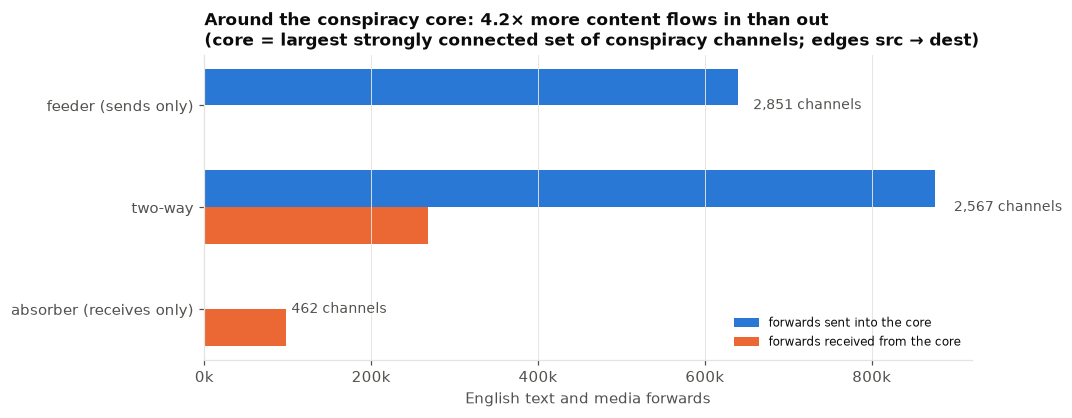

In [6]:
a_en = A[A.scope == "English–English"].drop(index="CORE").drop(index="no direct tie")
fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(a_en))
ax.barh(y - 0.18, a_en.forwards_to_core, height=0.36, color=plots.SERIES[0], label="forwards sent into the core")
ax.barh(y + 0.18, a_en.forwards_from_core, height=0.36, color=plots.SERIES[1], label="forwards received from the core")
for yi, (n, t, f) in enumerate(zip(a_en.channels, a_en.forwards_to_core, a_en.forwards_from_core)):
    ax.text(max(t, f) * 1.02 + 5e3, yi, f"{int(n):,} channels", va="center", fontsize=9, color=plots.INK_2)
ax.set_yticks(y, a_en.index); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(lambda v, _: f"{v / 1e3:,.0f}k")
ratio = a_en.forwards_to_core.sum() / a_en.forwards_from_core.sum()
ax.set_xlabel("English text and media forwards")
ax.set_title(f"Around the conspiracy core: {ratio:.1f}× more content flows in than out\n"
             f"(core = largest strongly connected set of conspiracy channels; edges src → dest)", loc="left")
ax.legend(loc="lower right", fontsize=8)
plots.savefig(fig, "02d_fig1_conspiracy_core", OUT)
plt.show()

In [7]:
# ---------- B. community-level bow-tie
comm = pd.read_parquet(cfg.DERIVED / "communities.parquet").set_index("channel_id").community
cshare = channels.join(comm, how="inner").groupby("community").conspiracy.mean()
csize = comm.value_counts()
ce = (edges.assign(a=edges.src_id.map(comm), b=edges.dest_id.map(comm)).query("a != b")
      .groupby(["a", "b"]).weight.sum().reset_index())
ce["share_of_src_export"] = ce.weight / ce.groupby("a").weight.transform("sum")

def bowtie_ids(src, dst, ids):
    idx = {c: i for i, c in enumerate(ids)}
    g = ig.Graph(n=len(ids), edges=[(idx[a], idx[b]) for a, b in zip(src, dst)], directed=True)
    scc = g.connected_components(mode="strong")
    core = np.asarray(scc.membership) == np.argmax(scc.sizes())
    v = int(np.flatnonzero(core)[0])
    ro = np.zeros(len(ids), bool); ro[g.subcomponent(v, mode="out")] = True
    ri = np.zeros(len(ids), bool); ri[g.subcomponent(v, mode="in")] = True
    return pd.Series(np.where(core, "CORE", np.where(ri, "IN", np.where(ro, "OUT", "OTHER"))), index=ids)

ids = np.sort(csize.index.to_numpy())
resB = []
for tau in [0.0, 0.01, 0.05]:
    k = ce[ce.share_of_src_export >= tau]
    part = bowtie_ids(k.a, k.b, ids)
    for p in PARTS:
        m = part.index[part == p]
        big = [c for c in m if csize[c] >= 1000]
        resB.append({"tau": tau, "part": p, "communities": len(m), "channels": int(csize[m].sum()),
                     "conspiracy_share": channels.join(comm, how="inner").query("community in @m").conspiracy.mean() if len(m) else np.nan,
                     "large communities (≥ 1,000 ch.)": ", ".join(f"C{c} ({cshare[c]:.0%})" for c in sorted(big))})
B = pd.DataFrame(resB)
B.style.format({"channels": "{:,}", "conspiracy_share": "{:.1%}", "tau": "{:.0%}"}).hide(axis="index")

tau,part,communities,channels,conspiracy_share,"large communities (≥ 1,000 ch.)"
0%,IN,67,228,5.7%,
0%,CORE,215,"120,461",9.6%,"C0 (5%), C1 (3%), C2 (1%), C3 (0%), C4 (4%), C5 (51%), C6 (35%), C7 (67%), C8 (1%), C9 (1%), C10 (3%), C11 (1%), C12 (38%), C13 (1%), C14 (2%), C15 (5%), C16 (0%), C17 (2%)"
0%,OUT,3,9,0.0%,
0%,OTHER,4,17,0.0%,
1%,IN,239,"4,906",0.9%,C16 (0%)
1%,CORE,43,"115,783",10.0%,"C0 (5%), C1 (3%), C2 (1%), C3 (0%), C4 (4%), C5 (51%), C6 (35%), C7 (67%), C8 (1%), C9 (1%), C10 (3%), C11 (1%), C12 (38%), C13 (1%), C14 (2%), C15 (5%), C17 (2%)"
1%,OUT,0,0,nan%,
1%,OTHER,7,26,0.0%,
5%,IN,261,"47,092",2.1%,"C2 (1%), C3 (0%), C8 (1%), C9 (1%), C11 (1%), C13 (1%), C14 (2%), C15 (5%)"
5%,CORE,13,"71,907",14.8%,"C0 (5%), C1 (3%), C4 (4%), C5 (51%), C6 (35%), C7 (67%), C10 (3%), C12 (38%), C17 (2%)"


In [8]:
# ---------- C. channel-level bow-tie with a minimum edge weight
resC = []
for s, e in [("full graph", edges), ("English–English", edges_en)]:
    for kmin in [1, 5, 20, 100]:
        ek = e[e.weight >= kmin]
        part = bowtie(ek)
        ch = channels.loc[part.index]
        for p in PARTS:
            m = part.to_numpy() == p
            resC.append({"scope": s, "min_weight": kmin, "part": p, "channels": int(m.sum()),
                         "share_of_channels_in_graph": m.mean(),
                         "conspiracy_share": ch.conspiracy.to_numpy()[m].mean() if m.any() else np.nan,
                         "share_of_conspiracy_in_graph": ch.conspiracy.to_numpy()[m].sum() / ch.conspiracy.sum()})
C = pd.DataFrame(resC)
print(C.pivot_table(index=["scope", "min_weight"], columns="part", values="share_of_channels_in_graph").reindex(columns=PARTS)
      .map(lambda v: f"{v:.1%}").to_string())
print()
print(C.pivot_table(index=["scope", "min_weight"], columns="part", values="conspiracy_share").reindex(columns=PARTS)
      .map(lambda v: "—" if pd.isna(v) else f"{v:.0%}").to_string())

part                           IN   CORE    OUT  OTHER
scope           min_weight                            
English–English 1           29.3%  65.8%   2.1%   2.7%
                5           29.9%  46.2%  11.1%  12.7%
                20          16.7%  19.6%  13.5%  50.2%
                100          4.4%   3.0%  15.9%  76.7%
full graph      1           25.2%  74.6%   0.2%   0.1%
                5           30.3%  50.3%  13.0%   6.3%
                20          21.8%  24.8%  21.5%  31.9%
                100          6.1%   3.7%  15.2%  75.0%

part                         IN CORE  OUT OTHER
scope           min_weight                     
English–English 1            7%  37%  20%    3%
                5           15%  45%  45%    6%
                20          38%  80%  79%    8%
                100         71%  90%  97%   29%
full graph      1            2%  12%  16%    3%
                5            4%  17%  14%    2%
                20          10%  27%  22%    4%
                1

## 4 · Bow-tie diagrams

**Figure 2.** The classic bow-tie picture (Broder et al. 2000) for the two informative variants, English–
English graph. Each part is drawn with size ∝ √channels and coloured by its share of conspiracy-labeled
channels (blue = none, orange = all); arrows are content flows (width ∝ √forwards; edges `src -> dest`).
(a) Conspiracy-centred (variant A): IN = feeders, OUT = absorbers, top = two-way channels, bottom =
channels with no direct tie. (b) Strong ties only (variant C, edges with ≥ 20 forwards).

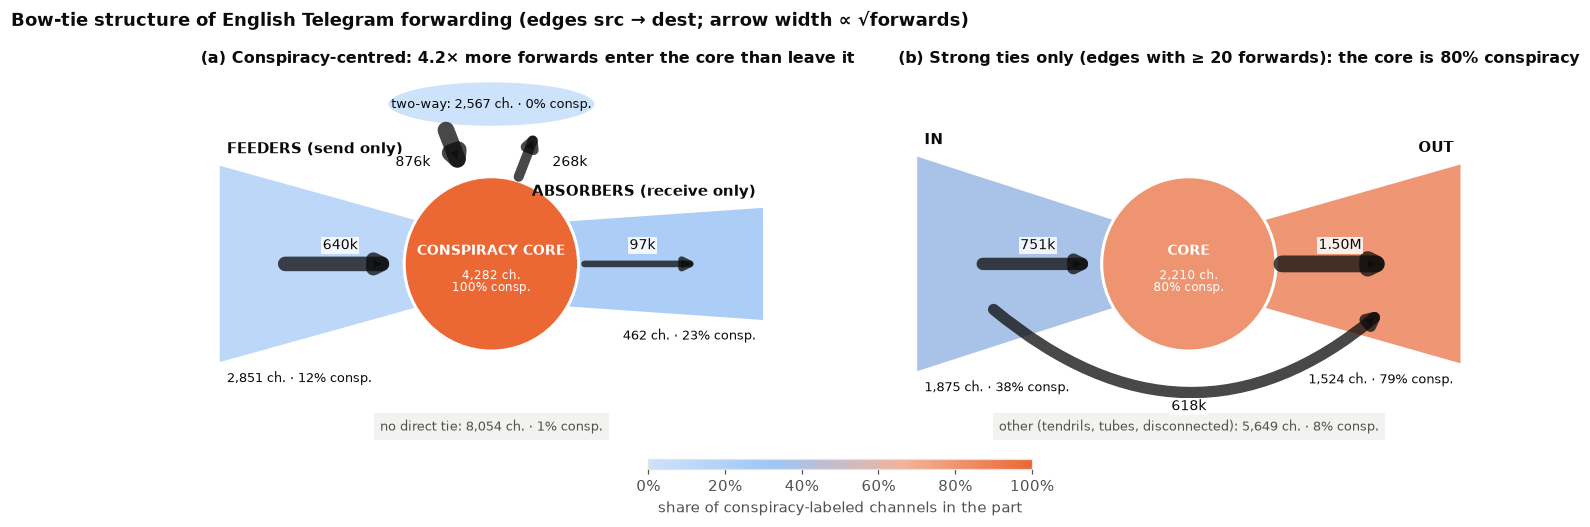

flows (b): {'CORE→CORE': '2,778,387', 'CORE→OUT': '1,499,461', 'IN→CORE': '750,847', 'IN→IN': '862,251', 'IN→OTHER': '500,020', 'IN→OUT': '617,697', 'OTHER→OTHER': '3,458,533', 'OTHER→OUT': '35,249', 'OUT→OUT': '41,006'}


In [9]:
from matplotlib.patches import Circle, Ellipse, FancyArrowPatch, Polygon, FancyBboxPatch
from matplotlib.colors import LinearSegmentedColormap
CMAP = LinearSegmentedColormap.from_list("consp", ["#cde2fb", "#9ec5f4", "#f2b39a", plots.SERIES[1]])

def k_fmt(v):
    return f"{v / 1e6:.2f}M" if v >= 1e6 else f"{v / 1e3:.0f}k"

def bowtie_diagram(ax, parts, flows, title):
    nmax = max(p["n"] for k, p in parts.items() if k in ("IN", "CORE", "OUT", "TWO"))
    fmax = max(flows.values()) if flows else 1
    cx, cy = 5.0, 3.0
    rc = 0.75 + 0.75 * np.sqrt(parts["CORE"]["n"] / nmax)
    def lobe(side, p):
        h = 0.5 + 1.5 * np.sqrt(p["n"] / nmax)
        x_out = 0.3 if side < 0 else 9.7
        x_in = cx + side * rc * 0.8
        ax.add_patch(Polygon([(x_out, cy + h), (x_in, cy + rc * 0.5), (x_in, cy - rc * 0.5), (x_out, cy - h)],
                             closed=True, fc=CMAP(p["consp"]), ec="white", lw=2, zorder=1))
        tx, ha = (x_out + 0.15, "left") if side < 0 else (x_out - 0.15, "right")
        ax.text(tx, cy + h + 0.12, p["label"], ha=ha, va="bottom", fontsize=9.5, fontweight="bold", color=plots.INK, zorder=5)
        ax.text(tx, cy - h - 0.12, f"{p['n']:,} ch. · {p['consp']:.0%} consp.", ha=ha, va="top", fontsize=8.5, color=plots.INK, zorder=5)
    lobe(-1, parts["IN"]); lobe(+1, parts["OUT"])
    ax.add_patch(Circle((cx, cy), rc, fc=CMAP(parts["CORE"]["consp"]), ec="white", lw=2, zorder=2))
    ax.text(cx, cy + 0.22, parts["CORE"]["label"], ha="center", va="center", fontsize=9, fontweight="bold", color="white", zorder=5)
    ax.text(cx, cy - 0.3, f"{parts['CORE']['n']:,} ch.\n{parts['CORE']['consp']:.0%} consp.", ha="center", va="center",
            fontsize=8, color="white", zorder=5, linespacing=1.1)
    def arrow(p0, p1, f, rad=0.0, label_xy=None):
        ax.add_patch(FancyArrowPatch(p0, p1, arrowstyle="-|>", mutation_scale=14, lw=1 + 10 * np.sqrt(f / fmax),
                                     color=plots.INK, alpha=0.75, connectionstyle=f"arc3,rad={rad}", zorder=4))
        if label_xy:
            ax.text(*label_xy, k_fmt(f), ha="center", va="center", fontsize=9, color=plots.INK, zorder=6,
                    bbox=dict(fc="white", ec="none", alpha=0.85, pad=1))
    if flows.get(("IN", "CORE")):
        arrow((1.4, cy), (cx - rc - 0.05, cy), flows[("IN", "CORE")], label_xy=(2.4, cy + 0.32))
    if flows.get(("CORE", "OUT")):
        arrow((cx + rc + 0.05, cy), (8.6, cy), flows[("CORE", "OUT")], label_xy=(7.6, cy + 0.32))
    if flows.get(("IN", "OUT")):
        arrow((1.6, cy - 0.75), (8.4, cy - 0.75), flows[("IN", "OUT")], rad=0.42, label_xy=(5.0, cy - rc - 0.95))
    if "TWO" in parts:
        p = parts["TWO"]
        ax.add_patch(Ellipse((cx, 5.75), 3.6, 0.8, fc=CMAP(p["consp"]), ec="white", lw=2, zorder=1))
        ax.text(cx, 5.75, f"{p['label']}: {p['n']:,} ch. · {p['consp']:.0%} consp.", ha="center", va="center", fontsize=8.5, color=plots.INK, zorder=5)
        arrow((cx - 0.8, 5.35), (cx - 0.45, cy + rc - 0.05), flows[("TWO", "CORE")], label_xy=(cx - 1.35, 4.75))
        arrow((cx + 0.45, cy + rc - 0.05), (cx + 0.8, 5.35), flows[("CORE", "TWO")], label_xy=(cx + 1.35, 4.75))
    if "OTHER" in parts:
        p = parts["OTHER"]
        ax.text(cx, 0.2, f"{p['label']}: {p['n']:,} ch. · {p['consp']:.0%} consp.", ha="center", va="center", fontsize=8.5,
                color=plots.INK_2, bbox=dict(fc="#f2f2f0", ec="none", pad=4))
    ax.set_xlim(0, 10); ax.set_ylim(-0.2, 6.3); ax.set_aspect("equal"); ax.axis("off")
    ax.set_title(title, loc="left", fontsize=10.5)

# (a) conspiracy-centred, English
a_en = A[A.scope == "English–English"]
pa = {"IN": dict(label="FEEDERS (send only)", n=int(a_en.loc["feeder (sends only)", "channels"]), consp=float(a_en.loc["feeder (sends only)", "conspiracy_share"])),
      "CORE": dict(label="CONSPIRACY CORE", n=int(a_en.loc["CORE", "channels"]), consp=1.0),
      "OUT": dict(label="ABSORBERS (receive only)", n=int(a_en.loc["absorber (receives only)", "channels"]), consp=float(a_en.loc["absorber (receives only)", "conspiracy_share"])),
      "TWO": dict(label="two-way", n=int(a_en.loc["two-way", "channels"]), consp=float(a_en.loc["two-way", "conspiracy_share"])),
      "OTHER": dict(label="no direct tie", n=int(a_en.loc["no direct tie", "channels"]), consp=float(a_en.loc["no direct tie", "conspiracy_share"]))}
fa = {("IN", "CORE"): float(a_en.loc["feeder (sends only)", "forwards_to_core"]),
      ("CORE", "OUT"): float(a_en.loc["absorber (receives only)", "forwards_from_core"]),
      ("TWO", "CORE"): float(a_en.loc["two-way", "forwards_to_core"]),
      ("CORE", "TWO"): float(a_en.loc["two-way", "forwards_from_core"])}

# (b) strong ties only, English (variant C, k >= 20)
ek = edges_en[edges_en.weight >= 20]
part = bowtie(ek)
cs = channels.conspiracy.reindex(part.index).groupby(part.to_numpy()).mean()
ns = part.value_counts()
fl = ek.assign(a=ek.src_id.map(part), b=ek.dest_id.map(part)).groupby(["a", "b"]).weight.sum()
pb = {p: dict(label=p if p != "OTHER" else "other (tendrils, tubes, disconnected)", n=int(ns.get(p, 0)), consp=float(cs.get(p, 0)))
      for p in PARTS}
fb = {k: float(fl.get(k, 0)) for k in [("IN", "CORE"), ("CORE", "OUT"), ("IN", "OUT")]}

fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
bowtie_diagram(axes[0], pa, fa, f"(a) Conspiracy-centred: {(fa[('IN', 'CORE')] + fa[('TWO', 'CORE')]) / (fa[('CORE', 'OUT')] + fa[('CORE', 'TWO')]):.1f}× more forwards enter the core than leave it")
bowtie_diagram(axes[1], pb, fb, f"(b) Strong ties only (edges with ≥ 20 forwards): the core is {pb['CORE']['consp']:.0%} conspiracy")
sm = plt.cm.ScalarMappable(cmap=CMAP, norm=plt.Normalize(0, 1))
cb = fig.colorbar(sm, ax=axes, location="bottom", shrink=0.3, aspect=40, pad=0.02, format=lambda v, _: f"{v:.0%}")
cb.set_label("share of conspiracy-labeled channels in the part")
fig.suptitle("Bow-tie structure of English Telegram forwarding (edges src → dest; arrow width ∝ √forwards)",
             x=0.01, ha="left", fontsize=11.5, fontweight="bold")
plots.savefig(fig, "02d_fig2_bowtie_diagrams", OUT)
plt.show()
print("flows (b):", {f"{a}→{b}": f"{v:,.0f}" for (a, b), v in fl.items()})